# Learning Gaussian Processes with Randomized Quantum Local Kernels — a reproduction walkthrough

**Paper.** A. Aaraba, S. Cherkaoui, O. Ahmad, J.-F. Laprade, S. Wang, *Learning Gaussian Processes with Randomized Quantum Local Kernels*, IEEE QCNC 2026, pp. 660-667, [doi:10.1109/QCNC69040.2026.00108](https://doi.org/10.1109/QCNC69040.2026.00108).

This notebook builds the argument step by step:

- what the paper claims;
- how we test it;
- what reproduces;
- what survives the controls;
- how it compares with fair classical baselines;
- what a photonic (MerLin) version looks like.

**How evidence is produced.** Two kinds of cells appear below:

- **Live** cells run small, clearly labelled experiments on your CPU. The whole notebook takes a few minutes.
- **Stored** cells load the full 15-run sweeps from `results/all_runs_metrics.csv` and the other curated files in `results/`. Every stored number traces back to validated runs listed in `LOG.md`.

| § | Section |
|---|---|
| 1 | Problem statement and paper claim |
| 2 | Data, splits, metrics, and evaluation protocol |
| 3 | The method in equations |
| 4 | Known-answer sanity checks |
| 5 | Pipeline walkthrough |
| 6 | Small live experiment |
| 7 | Headline reproduction result (Table I) |
| 8 | Fair baseline comparison |
| 9 | Controls and ablations |
| 10 | Robustness and uncertainty |
| 11 | Photonic assessment (MerLin adaptation) |
| 12 | Claim-level conclusion and limitations |

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT = Path.cwd()
assert (PROJECT / "lib").is_dir(), (
    "Run this notebook from papers/randomized_quantum_local_kernels_gp/"
)
REPO = PROJECT.parents[1]
for path in (REPO, PROJECT.parent):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
# Reusable implementation lives in lib/; the notebook only orchestrates.
from randomized_quantum_local_kernels_gp.lib.circuits import (
    RingArchitecture,
    sample_parameter_draws,
    simulate_states,
)
from randomized_quantum_local_kernels_gp.lib.classical_baselines import (
    fit_parametric_gp,
    parametric_gram,
    rff_dictionary_features,
)
from randomized_quantum_local_kernels_gp.lib.data import make_dataset
from randomized_quantum_local_kernels_gp.lib.evaluation import evaluate_mixture
from randomized_quantum_local_kernels_gp.lib.features import (
    code_gaussian_features,
    exact_features,
    observable_supports,
    pauli_shadow_features,
)
from randomized_quantum_local_kernels_gp.lib.gp import factorize
from randomized_quantum_local_kernels_gp.lib.kernels import (
    cosine_wrapper_gram,
    nonstationary_lengthscale,
    query_kernel_matrix,
)
from randomized_quantum_local_kernels_gp.lib.mkl import (
    MKLSettings,
    _exact_gradient,
    fit_mixtures,
    mixture_gram,
)
from randomized_quantum_local_kernels_gp.lib.photonic_features import (
    PhotonicArchitecture,
    build_layer,
    encoding_phases,
    outcome_probabilities,
    photonic_features,
    sample_photonic_draws,
)

RESULTS = PROJECT / "results"
RUNS = pd.read_csv(RESULTS / "all_runs_metrics.csv")
KERNELS = ["rbf", "matern32", "nonstat_ls"]
COLORS = {
    "qubit": "tab:blue",
    "qubit_exact": "tab:cyan",
    "photonic": "tab:purple",
    "rff": "tab:orange",
    "rbfdict": "tab:green",
    "oracle": "black",
    "rbfgp": "tab:gray",
    "uniform": "tab:olive",
}
NOTEBOOK_START = time.perf_counter()
print(
    f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}"
)
print(
    f"Stored results: {RUNS['sweep'].nunique()} sweeps, {RUNS.groupby('sweep')['run_id'].nunique().sum()} runs"
)

Python 3.13.15, numpy 2.5.3, pandas 3.0.5
Stored results: 18 sweeps, 260 runs


## 1. Problem statement and paper claim

**Problem.** A Gaussian process (GP) is only as good as its covariance kernel, and choosing one is hard when correlations are unknown or non-stationary.

**The paper's idea.** Use a quantum device as a *generator* of many simple kernels:

1. Draw R = 128 random shallow 4-qubit circuits.
2. Measure few-body local Pauli expectations as features.
3. Wrap each feature map into a kernel.
4. Let a classical GP learn a convex mixture of the kernels by maximizing the marginal likelihood.

**Claims under test.**

| ID | Claim | Paper evidence |
|---|---|---|
| C1/C2 | The learned mixture approximates stationary (RBF, Matérn 3/2) and non-stationary covariances with high test kernel alignment | Table I: 0.9791 / 0.9920 / 0.9538 |
| C3 | Test predictions follow the targets with high fidelity and well-calibrated uncertainty | Fig. 4 (qualitative) |
| C4 | N = 10 000 classical-shadow snapshots keep the feature error below 0.06 | Sec. V text |
| — | Implicit: a useful family of GP covariance learners ("difficult to emulate with shallow classical models") | Introduction, motivation only |

**Falsifiable research question.** Does the quantum local-kernel mixture reach Table I's alignment under the paper's protocol, and do its predictions match a size-matched classical kernel dictionary?

**What would weaken the claims:**

- Table I values outside the run-to-run spread of a faithful reimplementation.
- High alignment that trivial controls also reach, such as uniform weights.
- A shadow error well above 0.06 under a correct shadow simulation.
- Classical baselines of matched size matching or beating the quantum mixture on predictive metrics.

In [3]:
PAPER_TABLE1 = {"rbf": 0.9791, "matern32": 0.9920, "nonstat_ls": 0.9538}
pd.DataFrame({"paper Table I (centered test alignment, one run)": PAPER_TABLE1})

,"paper Table I (centered test alignment, one run)"
rbf,0.9791
matern32,0.9920
nonstat_ls,0.9538


## 2. Data, splits, metrics, and evaluation protocol

**Data** (synthetic, generated in code; `lib/data.py` reimplements the authors' generator):

- M = 500 inputs x ~ U[−1, 1].
- For each query kernel κ*, labels y ~ N(0, K* + σ²I) with σ² = 0.002.
- The **first 375 points are training data and the last 125 test data**, as in the authors' notebook. The inputs are i.i.d., so this prefix split is a random split.
- Test labels are used **only** in the final metrics. Nothing (weights, σ², restarts, configs) is selected on test data.

**Important deviation from the paper text.** The paper prints lengthscale 0.2 and non-stationary slope c = 0.2. The authors' notebook, whose saved output *is* Table I, uses **ℓ = 0.3 and c = 2.0** with the sigmoid sign reversed. The cells below show why only the code settings can produce the paper's Fig. 3. We follow the code for the headline comparison; the printed settings are run as a control in §9.

inputs (500, 1), labels (3, 500), train 375, test 125


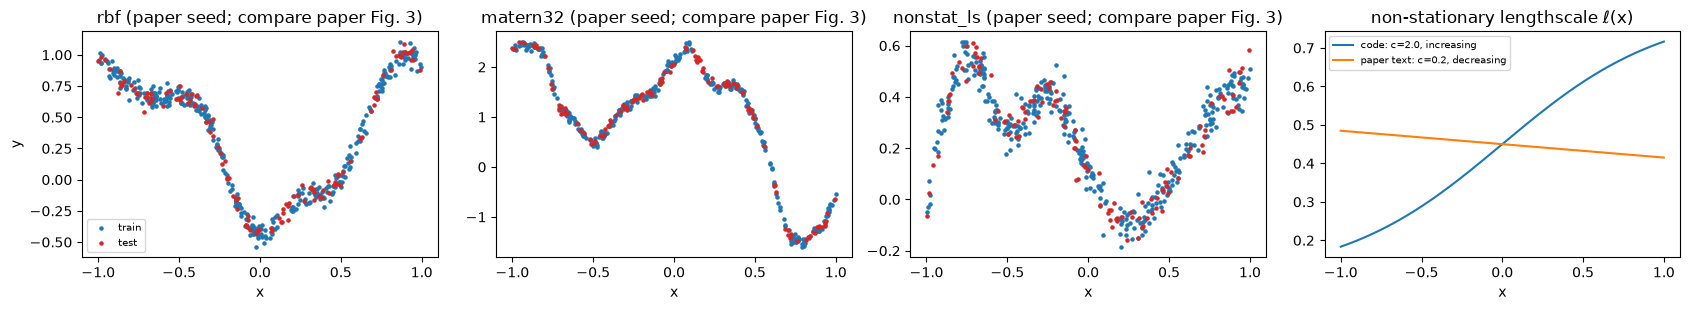

In [4]:
CODE_KERNELS = [
    {"name": "rbf", "type": "rbf", "params": {"lengthscale": 0.3}},
    {"name": "matern32", "type": "matern32", "params": {"lengthscale": 0.3}},
    {
        "name": "nonstat_ls",
        "type": "nonstat_ls",
        "params": {"ell_min": 0.1, "ell_max": 0.8, "c": 2.0, "sigmoid_sign": 1},
    },
]
DATA_CFG = {
    "data": {
        "num_points": 500,
        "input_dim": 1,
        "noise_variance": 0.002,
        "train_fraction": 0.75,
        "seed": 12345,
        "query_kernels": CODE_KERNELS,
    }
}
dataset = make_dataset(DATA_CFG)
train, test = dataset.train_index, dataset.test_index
print(
    f"inputs {dataset.inputs.shape}, labels {dataset.labels.shape}, train {train.size}, test {test.size}"
)

xs = np.linspace(-1, 1, 201)[:, None]
paper_text = {"ell_min": 0.1, "ell_max": 0.8, "c": 0.2, "sigmoid_sign": -1}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, name, row in zip(axes[:3], dataset.kernel_names, dataset.labels):
    ax.scatter(dataset.inputs[train, 0], row[train], s=5, label="train")
    ax.scatter(dataset.inputs[test, 0], row[test], s=5, color="tab:red", label="test")
    ax.set_title(f"{name} (paper seed; compare paper Fig. 3)")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(fontsize=7)
axes[3].plot(
    xs[:, 0],
    nonstationary_lengthscale(xs, CODE_KERNELS[2]["params"]),
    label="code: c=2.0, increasing",
)
axes[3].plot(
    xs[:, 0],
    nonstationary_lengthscale(xs, paper_text),
    label="paper text: c=0.2, decreasing",
)
axes[3].set_title("non-stationary lengthscale ℓ(x)")
axes[3].set_xlabel("x")
axes[3].legend(fontsize=7)
plt.tight_layout()
plt.show()

- **Observation.** The regenerated data reproduce the paper's Fig. 3: same curves, extremes and noise pattern. An independent pixel-overlay check put 90-100% of our points on the paper's figure, against about 20% for the printed settings.
- **Observation.** The paper-text ℓ(x) only moves between 0.415 and 0.485, so that kernel is nearly stationary. The code's ℓ(x) moves between 0.18 and 0.72.
- **Inference.** Table I and Fig. 3 were produced with the code settings. The printed values are an error in the paper.
- **Remaining uncertainty.** Our paper-seed data are not bit-identical to the authors': NumPy/LAPACK `multivariate_normal` differs, and our train log-likelihood is 922 vs 930. The match holds at figure level.

**Metrics** (all computed on the 125 test points by `lib/evaluation.py`):

- **Centered kernel alignment** between the learned test Gram K and the true test Gram K*: ⟨HKH, HK*H⟩_F / (‖HKH‖_F ‖HK*H‖_F), with H = I − 11ᵀ/n. This is what the authors' code computes for Table I. The paper's Eq. 25 shows the *uncentered* version; we report both in the stored results.
- **RMSE**, **average negative log predictive density (NLPD)** and **2σ coverage** of the noisy test targets, under the predictive N(mean, var_f + σ²).

**Protocol.**

- Every stored configuration has 15 runs: data seeds {12345, 1, 2, 3, 4} × circuit-sampling (Sobol) seeds {12345, 1, 2}, with feature-noise seed 123. The tables report mean ± sample std.
- This is a *crossed* design, not 15 independent replicates; §10 checks robustness at the data-seed level.

## 3. The method in equations

**Circuit** (paper Eq. 3, 8, 9; Fig. 2). For draw r, on |+⟩^⊗4:

$$U(x,\theta_r)=\prod_{\ell=1}^{4}\Big[\textstyle\prod_q R_Y(\omega_{\ell q})\prod_{(i,j)\in\text{ring}}R_{ZZ}(\beta_{\ell,ij})\prod_q R_X(\alpha_{\ell q})\Big]\;\bigotimes_q R_Z(\delta_{\ell q}\,\xi_\ell x)$$

The input x is re-uploaded in every layer. The parameters θ_r = (δ, ξ, α, β, ω) come from a scrambled Sobol sequence: δ ∈ (−1, 1), angles ∈ (−π, π), |ξ| < π.

**Features** (Eq. 4-5). There are 24 local observables: X_q, Y_q, Z_q on each qubit and XX, YY, ZZ on each ring edge. The feature vector is φ_r(x) = (⟨O_j⟩)_j ∈ ℝ²⁴.

**Base kernel** (Eq. 21), a cosine wrapper:

$$\kappa_r(x,x')=\tfrac12\Big(1+\tfrac{\langle\phi_r(x),\phi_r(x')\rangle}{\|\phi_r(x)\|\,\|\phi_r(x')\|}\Big)\in[0,1]$$

**Mixture and objective** (Eq. 13-15). K = Σ_r w_r K^(r), with w = softmax(a). The noise is Σ = K + σ²I, and the objective is

$$\mathcal L=-\tfrac12 y^\top\Sigma^{-1}y-\tfrac12\log\det\Sigma-\tfrac{M}{2}\log 2\pi$$

Its gradient is ∂L/∂w_r = ½(αᵀK^(r)α − Tr[Σ⁻¹K^(r)]), with α = Σ⁻¹y, chained through the softmax.

**Optimizers.**

- **Authors' protocol** (reproduced from their code): backtracking ascent on the logits with a low-rank + Hutchinson approximate gradient, a 9-point log grid for σ² starting at 1, 3 rounds, and a quirk where every GP's weights are ascended at the *last* GP's σ².
- **Converged reference:** L-BFGS-B on (a, log σ²), not in the paper.

## 4. Known-answer sanity checks

These checks validate the components before they are trusted. They do **not** reproduce anything by themselves.

In [5]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.stats import multivariate_normal

arch = RingArchitecture(num_qubits=4, num_layers=4, input_dim=1)
params = sample_parameter_draws(arch, 4, seed=12345)[3]


def qiskit_circuit(arch):
    # The paper's circuit written independently in Qiskit (Eq. 8-9, Fig. 2).
    qc, x = QuantumCircuit(arch.num_qubits), ParameterVector("x", 1)
    qc.h(range(arch.num_qubits))
    for layer in range(arch.num_layers):
        xi, d, a = (
            ParameterVector(f"xi_{layer}", 1),
            ParameterVector(f"delta_{layer}", 4),
            ParameterVector(f"alpha_{layer}", 4),
        )
        b, w = ParameterVector(f"beta_{layer}", 4), ParameterVector(f"omega_{layer}", 4)
        for q in range(4):
            qc.rz(d[q] * xi[0] * x[0], q)
        for q in range(4):
            qc.rx(a[q], q)
        for e, (i, j) in enumerate(arch.ring_edges):
            qc.rzz(b[e], i, j)
        for q in range(4):
            qc.ry(w[q], q)
    return qc


qc = qiskit_circuit(arch)


def bind(x_value):
    values = {}
    for p in qc.parameters:
        name, index = p.name.split("[")
        if name == "x":
            values[p] = x_value
        else:
            group, layer = name.split("_")
            values[p] = float(getattr(params, group)[int(layer), int(index[:-1])])
    return values


xs_check = np.array([[-0.8], [0.1], [0.65]])
ours = simulate_states(arch, params, xs_check)
max_state_err = max(
    np.abs(ours[i] - Statevector(qc.assign_parameters(bind(x))).data).max()
    for i, x in enumerate(xs_check[:, 0])
)

features_ours = exact_features(ours[:1], 4)[0]
labels = []
for support in observable_supports(4):
    lab = ["I"] * 4
    for q, p in support:
        lab[3 - q] = p
    labels.append("".join(lab))
features_qiskit = np.array(
    [
        Statevector(ours[0]).expectation_value(SparsePauliOp(label)).real
        for label in labels
    ]
)

rng = np.random.default_rng(0)
xg = rng.uniform(-1, 1, (30, 1))
gram = query_kernel_matrix(xg, xg, "matern32", {"lengthscale": 0.3})
yg = rng.normal(size=30)
lml_err = abs(
    factorize(gram, 0.01, yg).log_marginal
    - multivariate_normal(np.zeros(30), gram + 0.01 * np.eye(30)).logpdf(yg)
)

grams3 = np.stack(
    [
        query_kernel_matrix(xg, xg, "rbf", {"lengthscale": ell})
        for ell in (0.05, 0.2, 0.6)
    ]
)
w0 = np.array([0.2, 0.5, 0.3])
analytic = _exact_gradient(grams3, factorize(mixture_gram(w0, grams3), 0.05, yg))
numeric = [
    (
        factorize(mixture_gram(w0 + h, grams3), 0.05, yg).log_marginal
        - factorize(mixture_gram(w0 - h, grams3), 0.05, yg).log_marginal
    )
    / 2e-6
    for h in np.eye(3) * 1e-6
]

pd.DataFrame(
    {
        "check": [
            "statevector vs Qiskit (max abs diff)",
            "24 local features vs Qiskit (max abs diff)",
            "GP log marginal vs SciPy MVN (abs diff)",
            "MKL gradient vs finite differences (max rel diff)",
        ],
        "value": [
            max_state_err,
            np.abs(features_ours - features_qiskit).max(),
            lml_err,
            np.max(np.abs(analytic - numeric) / np.abs(numeric)),
        ],
        "pass if below": [1e-10, 1e-10, 1e-8, 1e-5],
    }
)

,check,value,pass if below
0,statevector vs Qiskit (max abs diff),4.002966e-16,1.000000e-10
1,24 local features vs Qiskit (max abs diff),1.942890e-16,1.000000e-10
2,GP log marginal vs SciPy MVN (abs diff),3.922196e-12,1.000000e-08
3,MKL gradient vs finite differences (max rel diff),3.508254e-08,1.000000e-05


In [6]:
# Classical-shadow estimator: unbiased, with variance 3^k − μ² per snapshot,
# versus the authors' model (1 − μ²); single-group means over 300 repeats.
states = simulate_states(arch, params, np.array([[0.4]]))
mu = exact_features(states, 4)[0]
rng = np.random.default_rng(5)
shadow = np.stack(
    [pauli_shadow_features(states, 4, 400, 1, rng)[0] for _ in range(300)]
)
authors = np.stack(
    [code_gaussian_features(mu[None], 400, 1, rng)[0] for _ in range(300)]
)
k = np.array([len(s) for s in observable_supports(4)])
pd.DataFrame(
    {
        "observable locality k": k,
        "|mean shadow − exact| (should be ≈ 0)": np.abs(shadow.mean(0) - mu),
        "shadow var × N": shadow.var(0) * 400,
        "theory 3^k − μ²": 3.0**k - mu**2,
        "authors' model var × N": authors.var(0) * 400,
    }
).groupby("observable locality k").mean().round(3)

,|mean shadow − exact| (should be ≈ 0),shadow var × N,theory 3^k − μ²,authors' model var × N
observable locality k,,,,
1,0.003,3.012,2.962,0.938
2,0.007,8.826,8.909,0.886


- **Observation.** The simulator, features, likelihood and gradient agree with independent references to numerical precision. The true shadow estimator is unbiased, with per-snapshot variance ≈ 3^k − μ², while the authors' noise model has ≈ 1 − μ².
- **Inference.** The building blocks are correct. The authors' "shadow" model understates shot noise about 3× for 1-local features and about 9× for 2-local features.
- **Claim impact.** None yet. These checks are only component validation.

## 5. Pipeline walkthrough

Next we follow one input through the pipeline: circuit draws → local features → base kernels → mixture.

exact features (32, 500, 24) in 0.4 s


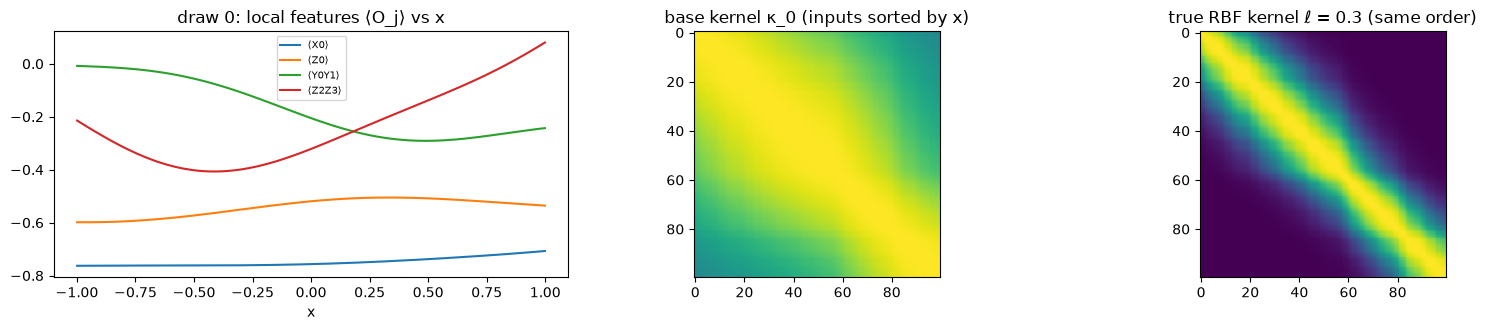

In [7]:
R_LIVE = 32
draws = sample_parameter_draws(arch, R_LIVE, seed=12345)
t0 = time.perf_counter()
features = np.stack(
    [exact_features(simulate_states(arch, p, dataset.inputs), 4) for p in draws]
)  # (R, M, 24)
print(f"exact features {features.shape} in {time.perf_counter() - t0:.1f} s")
grams_live = cosine_wrapper_gram(features, features)

order = np.argsort(dataset.inputs[:, 0])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for j in (0, 2, 13, 23):
    axes[0].plot(
        dataset.inputs[order, 0],
        features[0, order, j],
        label="⟨"
        + "".join(f"{pauli}{q}" for q, pauli in observable_supports(4)[j])
        + "⟩",
    )
axes[0].set_title("draw 0: local features ⟨O_j⟩ vs x")
axes[0].set_xlabel("x")
axes[0].legend(fontsize=7)
sub = order[::5]
axes[1].imshow(grams_live[0][np.ix_(sub, sub)], cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("base kernel κ_0 (inputs sorted by x)")
true_rbf = query_kernel_matrix(
    dataset.inputs[sub], dataset.inputs[sub], "rbf", {"lengthscale": 0.3}
)
axes[2].imshow(true_rbf, cmap="viridis", vmin=0, vmax=1)
axes[2].set_title("true RBF kernel ℓ = 0.3 (same order)")
plt.tight_layout()
plt.show()

- **Observation.** Each draw gives smooth, input-dependent local features. Its cosine kernel is a local similarity with a floor near ½ and some long-range structure.
- **Next step.** The mixture weights decide how these R kernels combine into an approximation of the true covariance.

## 6. Small live experiment (reduced: R = 32 instead of 128, exact features, paper seed)

This live run is a **reduction**: 32 base kernels instead of 128, exact features instead of 10 000-shot estimates, and a single seed. It shows the mechanism and lets you vary settings quickly. The decisive numbers come from the stored full sweeps in §7-§10.

The cell below fits both optimizers and a uniform-weight control, then evaluates them on the test split.

In [8]:
def settings(optimizer, coupling="per_kernel", max_iterations=400):
    if optimizer == "lbfgs":
        return MKLSettings(
            gradient="exact",
            max_iterations=2000,
            tolerance=1e-6,
            coordinate_rounds=3,
            initial_noise_variance=1.0,
            fit_noise_variance=True,
            optimizer="lbfgs",
        )
    return MKLSettings(
        gradient="lowrank_hutchinson",
        max_iterations=max_iterations,
        tolerance=1e-4,
        coordinate_rounds=3,
        initial_noise_variance=1.0,
        fit_noise_variance=True,
        approx_rank=32,
        hutchinson_probes=16,
        approx_seed=1028,
        optimizer="authors_protocol",
        noise_coupling=coupling,
    )


def evaluate(grams, weights, noise, k):
    spec = CODE_KERNELS[k]
    true_test = query_kernel_matrix(
        dataset.inputs[test], dataset.inputs[test], spec["type"], spec["params"]
    )
    return evaluate_mixture(
        grams,
        weights,
        noise,
        train,
        test,
        dataset.labels[k, train],
        dataset.labels[k, test],
        true_test,
    )


train_grams = grams_live[:, train][:, :, train]
targets = [dataset.labels[k, train] for k in range(3)]
rows = []
t0 = time.perf_counter()
fits = {
    "authors' protocol (shared σ²)": fit_mixtures(
        train_grams, targets, settings("authors", "authors_shared"), KERNELS
    ),
    "converged L-BFGS": fit_mixtures(train_grams, targets, settings("lbfgs"), KERNELS),
    "uniform weights (σ² grid only)": fit_mixtures(
        train_grams, targets, settings("authors", max_iterations=0), KERNELS
    ),
}
for method, results in fits.items():
    for k, res in enumerate(results):
        m = evaluate(grams_live, res.weights, res.noise_variance, k).metrics
        rows.append(
            {
                "method": method,
                "kernel": KERNELS[k],
                "train log marginal": res.log_marginal,
                "alignment": m["alignment_centered"],
                "RMSE": m["rmse"],
                "NLPD": m["avg_nlpd"],
                "2σ coverage": m["coverage_2sigma"],
            }
        )
print(f"fits + evaluation in {time.perf_counter() - t0:.1f} s")
live = pd.DataFrame(rows)
live.pivot(
    index="method", columns="kernel", values=["train log marginal", "alignment", "RMSE"]
).round(4)

fits + evaluation in 11.4 s


train log marginal                       \
kernel                                   matern32 nonstat_ls       rbf   
method                                                                   
authors' protocol (shared σ²)            143.8027   567.0574  573.4899   
converged L-BFGS                         327.0429   585.3673  591.0478   
uniform weights (σ² grid only)           220.2549   566.7361  571.9244   

                               alignment                        RMSE  \
kernel                          matern32 nonstat_ls     rbf matern32   
method                                                                 
authors' protocol (shared σ²)     0.9491     0.9533  0.9636   0.1301   
converged L-BFGS                  0.9669     0.9038  0.9677   0.0821   
uniform weights (σ² grid only)    0.9580     0.9748  0.9721   0.0963   

                                                   
kernel                         nonstat_ls     rbf  
method                                             
authors' protocol (shared σ²)      0.0482  0.0449  
converged L-BFGS                   0.0473  0.0447  
uniform weights (σ² grid only)     0.0480  0.0446

- **Observation** (live, reduced, single seed). Converged L-BFGS always reaches the highest train log marginal likelihood. Here the authors' protocol ends *below* the uniform-weight control on Matérn, by about 76 nats; in the stored 15-run sweeps it ends below it on RBF and non-stationary data (§9). Test alignment stays between 0.90 and 0.98 and does not rank the fits by likelihood: on non-stationary data the best-likelihood fit has the lowest alignment.
- **Inference.** The authors' optimizer does not fully maximize its own objective. It ascends the weights at the wrong noise level: σ² = 1 in round 1, then another GP's σ². Alignment alone does not tell these fits apart; RMSE does on Matérn (0.130 vs 0.082).
- **Remaining uncertainty.** This is one seed with R = 32. §7-§10 use the 15-run stored sweeps.

## 7. Headline reproduction result: Table I

**Stored full runs:** R = 128, the authors' noise model with N = 10 000, the authors' exact optimizer protocol including the shared-σ² quirk (sweep **S5**), and 15 runs. **S1** is the same protocol *without* the quirk.

In [9]:
def per_run(sweep, method="learned_mixture", metric="alignment_centered"):
    d = RUNS[(RUNS.sweep == sweep) & (RUNS.method == method)]
    return d.pivot_table(
        index=["data_seed", "sobol_seed"], columns="kernel", values=metric
    )


s5, s1 = per_run("S5_table1_original_sharednoise"), per_run("S1_table1_original")
table = pd.DataFrame(
    {
        "paper (1 run)": pd.Series(PAPER_TABLE1),
        "S5 mean": s5.mean(),
        "S5 std": s5.std(),
        "S5 runs ≥ paper": s5.ge(pd.Series(PAPER_TABLE1), axis=1).sum(),
        "(paper − S5 mean)/std": (pd.Series(PAPER_TABLE1) - s5.mean()) / s5.std(),
        "S1 (no quirk) mean": s1.mean(),
    }
).loc[KERNELS]
print(f"S5 runs: {len(s5)}  (data seeds × Sobol seeds)")
table.round(4)

S5 runs: 15  (data seeds × Sobol seeds)


,paper (1 run),S5 mean,S5 std,S5 runs ≥ paper,(paper − S5 mean)/std,S1 (no quirk) mean
rbf,0.9791,0.9717,0.0192,6,0.3866,0.9728
matern32,0.9920,0.9879,0.0092,5,0.4452,0.9758
nonstat_ls,0.9538,0.9585,0.0293,11,-0.1599,0.9585


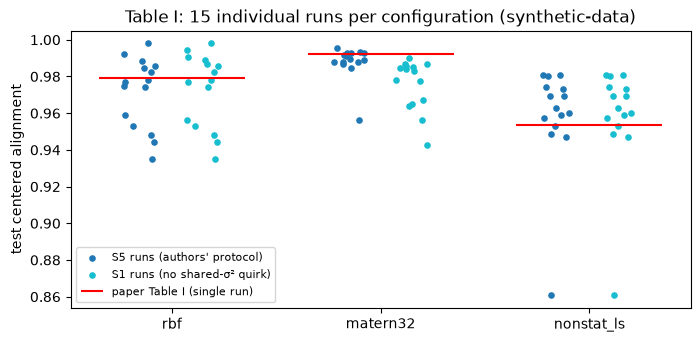

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, k in enumerate(KERNELS):
    jitter = np.random.default_rng(i).uniform(-0.08, 0.08, len(s5))
    ax.scatter(
        i + jitter - 0.15,
        s5[k],
        s=14,
        color=COLORS["qubit"],
        label="S5 runs (authors' protocol)" if i == 0 else None,
    )
    ax.scatter(
        i + jitter + 0.15,
        s1[k],
        s=14,
        color="tab:cyan",
        label="S1 runs (no shared-σ² quirk)" if i == 0 else None,
    )
    ax.hlines(
        PAPER_TABLE1[k],
        i - 0.35,
        i + 0.35,
        color="red",
        label="paper Table I (single run)" if i == 0 else None,
    )
ax.set_xticks(range(3), KERNELS)
ax.set_ylabel("test centered alignment")
ax.set_title("Table I: 15 individual runs per configuration (synthetic-data)")
ax.legend(fontsize=8, loc="lower left")
plt.show()

- **Observation.** All three paper values lie inside the S5 run distribution, within 0.45 run-std of the mean. Without the authors' shared-σ² quirk (S1), Matérn is systematically lower.
- **Inference.** **Table I is quantitatively reproduced**, but only with the authors' exact code protocol and data settings. The paper reports one run to 4 decimals, while the run-to-run std is 0.01-0.03.
- **Remaining uncertainty.** The data are not bit-identical to the authors'. The quirk is an implementation detail the paper does not describe.
- **Claim impact.** C1/C2: **reproduced** (metric agreement).

## 8. Fair baseline comparison

The paper has **no baseline**. The baselines below were declared *before* any baseline run (`LOG.md`, Phase 5 plan). The decision rule was fixed in advance: a difference counts only if its paired 95% bootstrap CI excludes 0 **and** it exceeds 0.01 alignment, 5% RMSE or 0.05 NLPD.

**Fairness by dimension** for the main comparison (quantum dictionary vs the B3 random-Fourier-feature dictionary):

| Dimension | Quantum dictionary (S6/S7) | B3 RFF dictionary (C2) | Matched? |
|---|---|---|---|
| Information and inputs | x only | x only | yes |
| Parameter count | 128 random circuits × 68 fixed parameters, plus 129 learned (weights + σ²) | 128 × 13 random numbers (1 lengthscale + 12 frequencies), plus 129 learned | **learned parameters matched**; generator parameters not |
| Feature dimension and wrapper | 24 features, cosine wrapper | 24 features (12 cos/sin pairs), cosine wrapper | yes |
| Training data | same 375 points | same | yes |
| Optimization | L-BFGS-B, ≤ 2000 iterations, converged | same | yes |
| Tuning budget | none (generator ranges from the paper) | none (frequency range fixed a priori from the B4 range [0.02, 2]) | yes (both untuned) |
| Compute and wall time | statevector simulation plus 10 000-shot estimation (S6) or exact (S7) | exact features, trivial cost | **not matched** (quantum costs far more) |
| Evaluation protocol | same split, metrics and code | same | yes |

Also run: **B4**, a dictionary of 128 RBF lengthscales; **B1**, a GP with the true kernel family fitted by ML-II (the oracle reference); and **B2**, a plain RBF GP (standard practice).

In [11]:
# Live mini-comparison on the paper seed (R = 32, reduced): RFF dictionary and the oracle GP.
rff, _ = rff_dictionary_features(
    dataset.inputs, R_LIVE, 24, sobol_seed=12345, lengthscale_range=(0.02, 2.0)
)
grams_rff = cosine_wrapper_gram(rff, rff)
rff_fits = fit_mixtures(
    grams_rff[:, train][:, :, train], targets, settings("lbfgs"), KERNELS
)
rows = []
for k, spec in enumerate(CODE_KERNELS):
    q = live[(live.method == "converged L-BFGS") & (live.kernel == KERNELS[k])].iloc[0]
    r = evaluate(grams_rff, rff_fits[k].weights, rff_fits[k].noise_variance, k).metrics
    fit = fit_parametric_gp(
        spec["type"],
        dataset.inputs[train],
        dataset.labels[k, train],
        restarts=5,
        seed=12345 + k,
        label=spec["name"],
    )
    o = evaluate(
        parametric_gram(fit.family, fit.params, dataset.inputs, dataset.inputs)[None],
        np.ones(1),
        fit.noise_variance,
        k,
    ).metrics
    rows += [
        {
            "system": "quantum dictionary (exact features)",
            "kernel": KERNELS[k],
            "alignment": q["alignment"],
            "RMSE": q["RMSE"],
        },
        {
            "system": "RFF dictionary",
            "kernel": KERNELS[k],
            "alignment": r["alignment_centered"],
            "RMSE": r["rmse"],
        },
        {
            "system": "true-family GP (oracle)",
            "kernel": KERNELS[k],
            "alignment": o["alignment_centered"],
            "RMSE": o["rmse"],
        },
    ]
pd.DataFrame(rows).pivot(
    index="system", columns="kernel", values=["alignment", "RMSE"]
).round(4)

alignment                        RMSE  \
kernel                               matern32 nonstat_ls     rbf matern32   
system                                                                      
RFF dictionary                         0.9080     0.9711  0.9524   0.0526   
quantum dictionary (exact features)    0.9669     0.9038  0.9677   0.0821   
true-family GP (oracle)                0.9781     0.9854  0.9976   0.0509   

                                                        
kernel                              nonstat_ls     rbf  
system                                                  
RFF dictionary                          0.0493  0.0446  
quantum dictionary (exact features)     0.0473  0.0447  
true-family GP (oracle)                 0.0475  0.0444

In [12]:
# Stored full comparison (15 runs per system), aggregated from the per-run table.
SYSTEMS = {
    "S6_table1_lbfgs": (
        "qubit dictionary, 10 000-shot features",
        "learned_mixture",
        "qubit",
    ),
    "S7_table1_exact_features_lbfgs": (
        "qubit dictionary, exact features",
        "learned_mixture",
        "qubit_exact",
    ),
    "M4_table1_merlin_mixed_lbfgs": (
        "photonic dictionary (MerLin adaptation)",
        "learned_mixture",
        "photonic",
    ),
    "C2_table1_classical_rff_lbfgs": ("B3 RFF dictionary", "learned_mixture", "rff"),
    "C4_table1_classical_rbfdict_lbfgs": (
        "B4 RBF dictionary",
        "learned_mixture",
        "rbfdict",
    ),
    "C5_table1_classical_gp_true": (
        "B1 true-family GP (oracle)",
        "parametric_gp",
        "oracle",
    ),
    "C6_table1_classical_gp_rbf": ("B2 RBF GP", "parametric_gp", "rbfgp"),
}
summary = []
for sweep, (name, method, _) in SYSTEMS.items():
    d = RUNS[(RUNS.sweep == sweep) & (RUNS.method == method)]
    for k in KERNELS:
        dk = d[d.kernel == k]
        summary.append(
            {
                "system": name,
                "kernel": k,
                "runs": len(dk),
                "alignment": f"{dk.alignment_centered.mean():.3f} ± {dk.alignment_centered.std():.3f}",
                "RMSE": f"{dk.rmse.mean():.4f} ± {dk.rmse.std():.4f}",
                "NLPD": f"{dk.avg_nlpd.mean():.3f} ± {dk.avg_nlpd.std():.3f}",
            }
        )
pd.DataFrame(summary).pivot(
    index="system", columns="kernel", values=["alignment", "RMSE"]
)

alignment                 \
kernel                                        matern32     nonstat_ls   
system                                                                  
B1 true-family GP (oracle)               0.993 ± 0.009  0.984 ± 0.017   
B2 RBF GP                                0.777 ± 0.039  0.945 ± 0.018   
B3 RFF dictionary                        0.925 ± 0.058  0.895 ± 0.048   
B4 RBF dictionary                        0.980 ± 0.009  0.931 ± 0.040   
photonic dictionary (MerLin adaptation)  0.964 ± 0.024  0.965 ± 0.014   
qubit dictionary, 10 000-shot features   0.986 ± 0.007  0.977 ± 0.003   
qubit dictionary, exact features         0.969 ± 0.020  0.957 ± 0.020   

                                                                   RMSE  \
kernel                                             rbf         matern32   
system                                                                    
B1 true-family GP (oracle)               0.998 ± 0.001  0.0499 ± 0.0012   
B2 RBF GP                                0.998 ± 0.001  0.0533 ± 0.0030   
B3 RFF dictionary                        0.921 ± 0.066  0.0516 ± 0.0019   
B4 RBF dictionary                        0.978 ± 0.017  0.0499 ± 0.0011   
photonic dictionary (MerLin adaptation)  0.981 ± 0.011  0.0840 ± 0.0112   
qubit dictionary, 10 000-shot features   0.981 ± 0.010  0.0976 ± 0.0122   
qubit dictionary, exact features         0.959 ± 0.026  0.0908 ± 0.0121   

                                                                           
kernel                                        nonstat_ls              rbf  
system                                                                     
B1 true-family GP (oracle)               0.0467 ± 0.0016  0.0454 ± 0.0033  
B2 RBF GP                                0.0469 ± 0.0019  0.0454 ± 0.0033  
B3 RFF dictionary                        0.0473 ± 0.0024  0.0454 ± 0.0033  
B4 RBF dictionary                        0.0470 ± 0.0021  0.0454 ± 0.0033  
photonic dictionary (MerLin adaptation)  0.0490 ± 0.0026  0.0468 ± 0.0033  
qubit dictionary, 10 000-shot features   0.0513 ± 0.0016  0.0493 ± 0.0043  
qubit dictionary, exact features         0.0469 ± 0.0018  0.0454 ± 0.0033

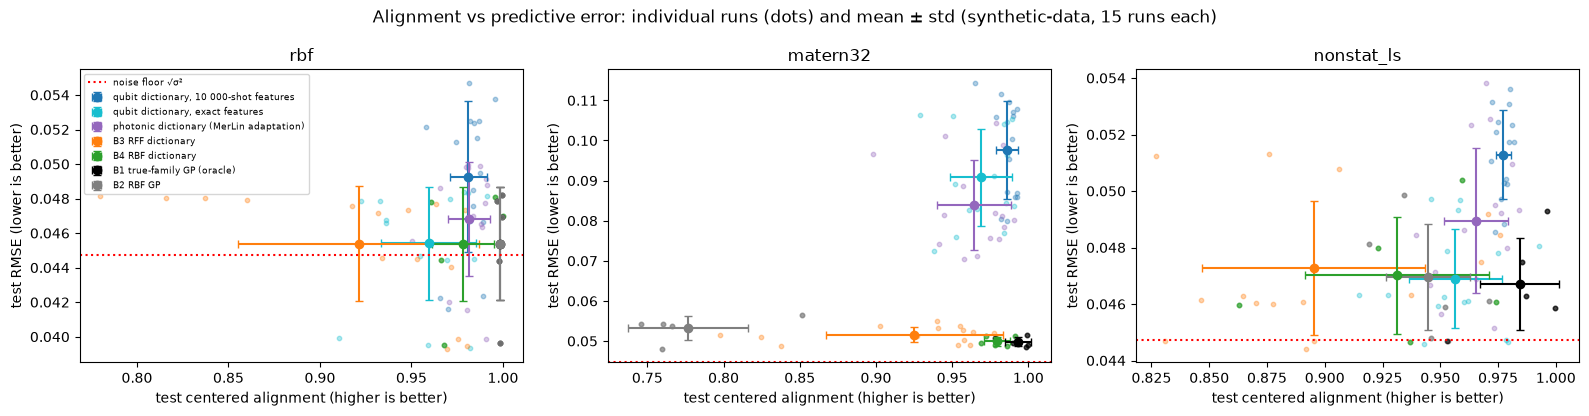

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, k in zip(axes, KERNELS):
    for sweep, (name, method, color) in SYSTEMS.items():
        d = RUNS[(RUNS.sweep == sweep) & (RUNS.method == method) & (RUNS.kernel == k)]
        ax.scatter(d.alignment_centered, d.rmse, s=10, alpha=0.35, color=COLORS[color])
        ax.errorbar(
            d.alignment_centered.mean(),
            d.rmse.mean(),
            xerr=d.alignment_centered.std(),
            yerr=d.rmse.std(),
            fmt="o",
            color=COLORS[color],
            capsize=3,
            label=name,
        )
    ax.axhline(np.sqrt(0.002), color="red", ls=":", label="noise floor √σ²")
    ax.set_title(k)
    ax.set_xlabel("test centered alignment (higher is better)")
    ax.set_ylabel("test RMSE (lower is better)")
axes[0].legend(fontsize=6.5)
fig.suptitle(
    "Alignment vs predictive error: individual runs (dots) and mean ± std (synthetic-data, 15 runs each)"
)
plt.tight_layout()
plt.show()

In [14]:
# Pre-declared pairwise decisions (generated by utils/compare_baselines.py; frozen rule).
import json

pairs = pd.DataFrame(
    json.loads((RESULTS / "phase5_comparison.json").read_text())["pairs"]
)
focus = pairs[
    pairs.B.isin(["C2_table1_classical_rff_lbfgs"])
    & pairs.A.isin(
        [
            "S6_table1_lbfgs",
            "S7_table1_exact_features_lbfgs",
            "M4_table1_merlin_mixed_lbfgs",
        ]
    )
]
focus.assign(ci95=focus.ci95.map(lambda c: f"[{c[0]:+.4f}, {c[1]:+.4f}]")).pivot(
    index=["A", "kernel"], columns="metric", values="verdict"
)

metric                                    alignment_centered  avg_nlpd  \
A                              kernel                                    
M4_table1_merlin_mixed_lbfgs   matern32             A better  B better   
                               nonstat_ls           A better  B better   
                               rbf                  A better       tie   
S6_table1_lbfgs                matern32             A better  B better   
                               nonstat_ls           A better  B better   
                               rbf                  A better  B better   
S7_table1_exact_features_lbfgs matern32             A better  B better   
                               nonstat_ls           A better       tie   
                               rbf                  A better       tie   

metric                                         rmse  
A                              kernel                
M4_table1_merlin_mixed_lbfgs   matern32    B better  
                               nonstat_ls       tie  
                               rbf              tie  
S6_table1_lbfgs                matern32    B better  
                               nonstat_ls  B better  
                               rbf         B better  
S7_table1_exact_features_lbfgs matern32    B better  
                               nonstat_ls       tie  
                               rbf              tie

- **Observation.**
  - On *prediction* (RMSE, NLPD), no quantum or photonic configuration beats any classical baseline.
  - With exact features (S7), the qubit dictionary **ties** the matched RFF dictionary on RBF and non-stationary data.
  - On Matérn, every quantum or photonic dictionary has about 1.7-2× the oracle's RMSE (0.084-0.098 vs 0.050), while all classical systems stay within 7% of the oracle.
  - On *alignment*, the quantum dictionaries beat the RFF dictionary.
- **Inference.**
  - Centered alignment is a weak proxy for predictive quality: the RFF dictionary has the lowest alignment of all dictionaries yet near-oracle RMSE.
  - The quantum alignment edge comes mostly from long-range ripple in the 12-frequency RFF kernels, which does not affect prediction.
- **Remaining uncertainty.** The RFF frequency range was fixed a priori, not tuned. Simulation cost differs enormously and is not matched.
- **Claim impact.** No quantum or photonic **advantage** is supported. The implicit claim of being a useful covariance learner is weakened to "competitive on smooth kernels".

## 9. Controls and ablations

These controls test explanations other than "the learned quantum mixture is a good covariance learner". All values come from stored 15-run sweeps unless marked live.

In [15]:
def stats(sweep, method="learned_mixture", metric="rmse"):
    return (
        RUNS[(RUNS.sweep == sweep) & (RUNS.method == method)]
        .groupby("kernel")[metric]
        .mean()
        .loc[KERNELS]
    )


controls = pd.DataFrame(
    {
        "S5 learned − uniform: train log marginal": stats(
            "S5_table1_original_sharednoise", metric="train_log_marginal"
        )
        - stats(
            "S5_table1_original_sharednoise", "uniform_mixture", "train_log_marginal"
        ),
        "S6 (converged) learned − uniform: train log marginal": stats(
            "S6_table1_lbfgs", metric="train_log_marginal"
        )
        - stats("S6_table1_lbfgs", "uniform_mixture", "train_log_marginal"),
        "S6 learned − uniform: alignment": stats(
            "S6_table1_lbfgs", metric="alignment_centered"
        )
        - stats("S6_table1_lbfgs", "uniform_mixture", "alignment_centered"),
        "S6 learned − uniform: NLPD": stats("S6_table1_lbfgs", metric="avg_nlpd")
        - stats("S6_table1_lbfgs", "uniform_mixture", "avg_nlpd"),
        "S7 exact − S6 shot features: RMSE": stats("S7_table1_exact_features_lbfgs")
        - stats("S6_table1_lbfgs"),
        "S7 exact − S6 shot features: alignment": stats(
            "S7_table1_exact_features_lbfgs", metric="alignment_centered"
        )
        - stats("S6_table1_lbfgs", metric="alignment_centered"),
    }
)
controls.T.round(4)

kernel,rbf,matern32,nonstat_ls
S5 learned − uniform: train log marginal,-16.8335,108.4170,-20.2797
S6 (converged) learned − uniform: train log marginal,32.6889,133.6461,35.3646
S6 learned − uniform: alignment,0.0021,0.0217,-0.0006
S6 learned − uniform: NLPD,0.1125,-0.2485,0.1271
S7 exact − S6 shot features: RMSE,-0.0039,-0.0068,-0.0044
S7 exact − S6 shot features: alignment,-0.0217,-0.0175,-0.0207


- **Uniform-weight control.** Under the authors' protocol, the learned mixture ends *below* uniform weights in train likelihood on RBF and non-stationary data. Once converged (S6) it is above uniform, yet test alignment barely moves and NLPD gets *worse*: 129 learned hyperparameters overfit. Learning clearly helps only on Matérn.
- **Shot-noise control (S7 vs S6).** Exact features give *lower* alignment but *better* RMSE. Shot noise inflates alignment and hurts prediction (σ² is underestimated).

In [16]:
# Classical shadows, live (reduced: 8 draws × 100 inputs × 24 features, N = 10 000, 16 median-of-means groups),
# then the stored full-size result (128 × 500 × 24).
rng = np.random.default_rng(123)
sub_inputs = dataset.inputs[:100]
exact_sub, authors_sub, shadow_sub = [], [], []
for p in draws[:8]:
    st = simulate_states(arch, p, sub_inputs)
    mu = exact_features(st, 4)
    exact_sub.append(mu)
    authors_sub.append(code_gaussian_features(mu, 10_000, None, rng))
    shadow_sub.append(pauli_shadow_features(st, 4, 10_000, None, rng))
exact_sub = np.stack(exact_sub)
stored = (
    RUNS[RUNS.kernel == "rbf"].groupby("sweep").feature_sup_norm.agg(["mean", "max"])
)
pd.DataFrame(
    {
        "live sup-norm error (8×100×24)": [
            np.abs(np.stack(authors_sub) - exact_sub).max(),
            np.abs(np.stack(shadow_sub) - exact_sub).max(),
        ],
        "stored mean over 15 full runs": [
            stored.loc["S1_table1_original", "mean"],
            stored.loc["S3_table1_pauli_shadow", "mean"],
        ],
        "stored max": [
            stored.loc["S1_table1_original", "max"],
            stored.loc["S3_table1_pauli_shadow", "max"],
        ],
        "paper claim": ["< 0.06", "< 0.06"],
    },
    index=["authors' noise model (code_gaussian)", "true single-qubit Pauli shadows"],
).round(4)

,live sup-norm error (8×100×24),stored mean over 15 full runs,stored max,paper claim
authors' noise model (code_gaussian),0.0581,0.0586,0.0595,< 0.06
true single-qubit Pauli shadows,0.1384,0.1780,0.1920,< 0.06


- **Observation.** With true Pauli shadows at N = 10 000, the sup-norm error over the full tensor is about 0.18, 3× the claim. The authors' figure (0.059) comes from a Gaussian direct-measurement noise model. The live reduced tensor has fewer entries, so its maximum is a bit smaller.
- **Inference.** **C4 is not reproduced (contradicted).** Real shadows need about 9 × 10⁴ snapshots for 0.06 (independent reviewer's estimate). Downstream (S3 − S1, paired): alignment changes are not significant, while RMSE worsens on all three kernels, most on Matérn (+0.020).

In [17]:
s8 = (RESULTS / "s8_bandwidth_characterization.md").read_text()
s4 = RUNS[(RUNS.sweep == "S4_table1_papertext_data")]
paper_text_ctrl = s4.pivot_table(
    index="method", columns="kernel", values="alignment_centered"
).loc[["learned_mixture", "uniform_mixture"], KERNELS]
print("Paper-text data settings (S4, ℓ = 0.2, c = 0.2): mean centered alignment")
display(paper_text_ctrl.round(3))

# Bandwidth: the highest frequency the paper's encoding can put into a feature
# is Σ_ℓ |ξ_ℓ| Σ_q |δ_ℓq| (rad per unit of x); Matérn 3/2 needs more.
bounds = [
    np.sum(np.abs(p.xi[:, 0]) * np.abs(p.delta).sum(axis=1))
    for p in sample_parameter_draws(arch, 128, seed=12345)
]
print(
    f"max feature frequency over 128 draws: median {np.median(bounds):.1f}, max {np.max(bounds):.1f} rad / unit x"
)
print(s8.split("Paired differences")[1])

Paper-text data settings (S4, ℓ = 0.2, c = 0.2): mean centered alignment


kernel,rbf,matern32,nonstat_ls
method,,,
learned_mixture,0.964,0.950,0.948
uniform_mixture,0.899,0.887,0.997


max feature frequency over 128 draws: median 12.5, max 23.1 rad / unit x
 S8 − S7 (same 5 seed pairs):

| Kernel | Δ RMSE | Δ NLPD | Δ alignment | runs with lower RMSE |
|---|---|---|---|---|
| rbf | +0.0002 | +0.0034 | +0.0081 | 2/5 |
| matern32 | -0.0369 | -0.5283 | -0.1175 | 5/5 |
| nonstat_ls | +0.0003 | +0.0067 | -0.0101 | 1/5 |



- **Paper-text settings (S4).** With the printed ℓ = 0.2, uniform weights fall to about 0.90 alignment on RBF and Matérn and learning adds about 0.065. The printed "non-stationary" kernel is so close to stationary that uniform weights already reach 0.997.
- **Bandwidth (S8; characterization, 5 runs).** The paper's encoding range caps feature frequencies near 12-23 rad per unit of x.
  - Scaling the inputs ×2.5 cuts Matérn RMSE from 0.091 to 0.054 (5/5 runs), close to the classical systems.
  - At the same time Matérn alignment *drops* from 0.98 to 0.87: alignment and prediction trade off.
- **Inference.** The Matérn prediction gap is a consequence of the paper's encoding design, not of quantum feature maps as such.

## 10. Robustness and uncertainty

- The 15 runs are a crossed 5 × 3 design. Deterministic baselines (B4) and ML-II GPs (B1/B2) barely vary across Sobol seeds, so their effective n is 5.
- We therefore repeat every pre-declared decision with data-seed means (n = 5).

In [18]:
robust = pd.DataFrame(
    json.loads((RESULTS / "phase5_comparison_dataseed.json").read_text())["pairs"]
)
merged = pairs.merge(
    robust,
    on=["A", "B", "kernel", "metric"],
    suffixes=(" (15 runs)", " (5 data seeds)"),
)
changed = merged[merged["verdict (15 runs)"] != merged["verdict (5 data seeds)"]]
print(
    f"{len(changed)} of {len(merged)} verdicts change; metrics affected: {sorted(changed.metric.unique())}"
)
changed[["A", "B", "kernel", "metric", "verdict (15 runs)", "verdict (5 data seeds)"]]

4 of 117 verdicts change; metrics affected: ['alignment_centered']


,A,B,kernel,metric,verdict (15 runs),verdict (5 data seeds)
15,S5_table1_original_sharednoise,C3_table1_classical_rbfdict,nonstat_ls,alignment_centered,A better,tie
18,M1_table1_merlin,C1_table1_classical_rff,rbf,alignment_centered,A better,tie
48,M2_table1_merlin_lbfgs,C2_table1_classical_rff_lbfgs,matern32,alignment_centered,A better,tie
81,S7_table1_exact_features_lbfgs,C2_table1_classical_rff_lbfgs,rbf,alignment_centered,A better,tie


In [19]:
spread = RUNS[
    RUNS.method.isin(["learned_mixture", "parametric_gp"])
    & RUNS.sweep.isin(list(SYSTEMS) + ["S5_table1_original_sharednoise"])
]
spread.groupby(["sweep", "kernel"]).alignment_centered.agg(
    ["count", "mean", "std", "min", "max"]
).unstack("kernel")["std"].round(4)

kernel,matern32,nonstat_ls,rbf
sweep,,,
C2_table1_classical_rff_lbfgs,0.0581,0.0484,0.0657
C4_table1_classical_rbfdict_lbfgs,0.0086,0.0398,0.0169
C5_table1_classical_gp_true,0.0086,0.0171,0.0012
C6_table1_classical_gp_rbf,0.0393,0.0181,0.0012
M4_table1_merlin_mixed_lbfgs,0.0244,0.0139,0.0114
S5_table1_original_sharednoise,0.0092,0.0293,0.0192
S6_table1_lbfgs,0.0072,0.0032,0.0100
S7_table1_exact_features_lbfgs,0.0203,0.0201,0.0258


- **Observation.** Only alignment verdicts change under data-seed aggregation (4 of 117, all wins becoming ties). Every prediction verdict is stable. Run-to-run alignment std is 0.003-0.03 for the quantum and photonic dictionaries.
- **Inference.** "Classical matches or beats quantum on prediction" is robust. "Quantum beats RFF on alignment" is weaker than the 15-run table suggests.
- **Remaining uncertainty.** The feature-noise seed (123) and Hutchinson seed (1028) were fixed, so their variability is not in the spread.

## 11. Photonic assessment (MerLin adaptation, not the paper's method)

**Status: `MERLIN_IMPLEMENTATION`** (simulated).

**Mapping.** Each dictionary entry becomes a fixed random linear-optical circuit on 12 modes with 4 photons, input |1,0,0,1,0,0,1,0,0,1,0,0⟩:

1. A fixed 50:50 beam-splitter brickwork.
2. Then 4 layers, each made of: data phase shifters PS(δ·ξ·x) on every mode, random phases, a nearest-neighbour beam-splitter brickwork, and random phases.

The features are local click parities ⟨Π_q⟩ and ⟨Π_qΠ_(q+1)⟩ (Π = (−1)^click, the analogue of Z / ZZ), estimated jointly from 10 000 threshold-detection events postselected on 4 distinct clicks. The kernel wrapper and MKL are unchanged.

**Why the initial brickwork matters.** Phases acting directly on a Fock input state are only a global phase. Without the brickwork, the first data layer does nothing. The first version (M1, M2) had this flaw; an independent review found it.

max change in outcome probabilities when perturbing layer-0 data phases: no initial mixing 3.8e-17, with balanced brickwork 3.5e-02


8 photonic draws × 500 inputs in 0.7 s; postselection probability 0.439; sampled-feature sup-norm error 0.049


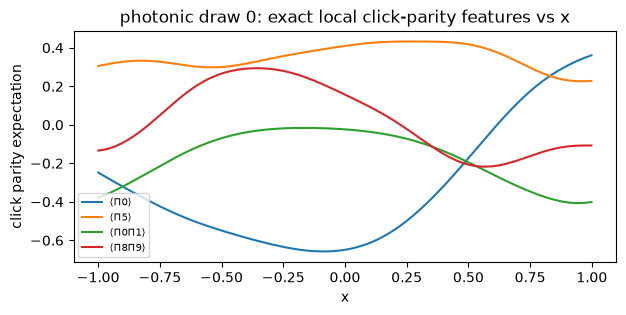

In [20]:
def layer0_effect(mixing):
    a = PhotonicArchitecture(
        num_modes=12, num_photons=4, num_layers=4, input_dim=1, initial_mixing=mixing
    )
    p = sample_photonic_draws(a, 1, seed=12345)[0]
    layer = build_layer(a, p, "threshold")
    phases = encoding_phases(a, p, np.array([[0.5]]))
    moved = phases.copy()
    moved[:, :12] += np.random.default_rng(0).uniform(
        -1, 1, 12
    )  # perturb only layer-0 data phases
    return np.abs(
        outcome_probabilities(layer, phases)[0] - outcome_probabilities(layer, moved)[0]
    ).max()


print(
    f"max change in outcome probabilities when perturbing layer-0 data phases: "
    f"no initial mixing {layer0_effect('none'):.1e}, with balanced brickwork {layer0_effect('balanced_brickwork'):.1e}"
)

parch = PhotonicArchitecture(
    num_modes=12,
    num_photons=4,
    num_layers=4,
    input_dim=1,
    initial_mixing="balanced_brickwork",
)
pdraws = sample_photonic_draws(parch, 8, seed=12345)
t0 = time.perf_counter()
out = [
    photonic_features(
        parch, p, dataset.inputs, "threshold", 10_000, np.random.default_rng(123)
    )
    for p in pdraws
]
print(
    f"8 photonic draws × 500 inputs in {time.perf_counter() - t0:.1f} s; "
    f"postselection probability {np.mean([o['postselection'].mean() for o in out]):.3f}; "
    f"sampled-feature sup-norm error {max(np.abs(o['used'] - o['exact']).max() for o in out):.3f}"
)
fig, ax = plt.subplots(figsize=(7, 3))
for j in (0, 5, 12, 20):
    ax.plot(
        dataset.inputs[order, 0],
        out[0]["exact"][order, j],
        label=f"⟨Π{j}⟩" if j < 12 else f"⟨Π{j - 12}Π{j - 11}⟩",
    )
ax.set_xlabel("x")
ax.set_ylabel("click parity expectation")
ax.set_title("photonic draw 0: exact local click-parity features vs x")
ax.legend(fontsize=7)
plt.show()

In [21]:
PAIRS_PH = {
    "converged MKL: M4 vs S6": ("M4_table1_merlin_mixed_lbfgs", "S6_table1_lbfgs"),
    "authors' protocol: M3 vs S5": (
        "M3_table1_merlin_mixed",
        "S5_table1_original_sharednoise",
    ),
}
rows = []
for label, (ph, qb) in PAIRS_PH.items():
    a_ph, a_qb = (
        stats(ph, metric="alignment_centered"),
        stats(qb, metric="alignment_centered"),
    )
    r_ph, r_qb = stats(ph), stats(qb)
    for k in KERNELS:
        rows.append(
            {
                "comparison": label,
                "kernel": k,
                "photonic alignment": a_ph[k],
                "qubit alignment": a_qb[k],
                "Δ alignment": a_ph[k] - a_qb[k],
                "RMSE ratio": r_ph[k] / r_qb[k],
                "within tolerance (|Δ| ≤ 0.02 and RMSE ±20%)": abs(a_ph[k] - a_qb[k])
                <= 0.02
                and abs(r_ph[k] / r_qb[k] - 1) <= 0.2,
            }
        )
pd.DataFrame(rows).round(4)

,comparison,kernel,photonic alignment,qubit alignment,Δ alignment,RMSE ratio,within tolerance (|Δ| ≤ 0.02 and RMSE ±20%)
0,converged MKL: M4 vs S6,rbf,0.9813,0.9811,0.0002,0.9503,True
1,converged MKL: M4 vs S6,matern32,0.9642,0.9862,-0.0219,0.8605,False
2,converged MKL: M4 vs S6,nonstat_ls,0.9653,0.9772,-0.0119,0.9545,True
3,authors' protocol: M3 vs S5,rbf,0.9378,0.9717,-0.0339,0.9886,False
4,authors' protocol: M3 vs S5,matern32,0.9496,0.9879,-0.0383,0.8819,False
5,authors' protocol: M3 vs S5,nonstat_ls,0.9125,0.9585,-0.0460,0.9844,False


**Hardware-aware settings (stored sweeps M3/M4):**

| Field | Value |
|---|---|
| Computation space | `UNBUNCHED` (postselected collision-free Fock distribution) |
| Detector | threshold |
| Photons / modes | 4 / 12 |
| Input state | \|1,0,0,1,0,0,1,0,0,1,0,0⟩ |
| Encoding | PS(δξx) on every mode, 4 layers, after an initial 50:50 brickwork |
| Postselection | 4 distinct clicks; success probability 0.437 on average (about 2.2× raw events per kept event) |
| Simulator | MerLin 0.4.1 analytic probabilities, NumPy multinomial sampling; **no hardware** |
| Shots | 10 000 kept events per (draw, input) |
| Seeds | 5 data × 3 Sobol, shot seed 123 |
| Loss / distinguishability | not modelled |

- **Observation.**
  - With converged MKL, the photonic dictionary is within the pre-declared tolerance of the qubit dictionary on RBF and non-stationary data. Matérn misses on alignment by 0.002, while its Matérn RMSE is *better* than qubit.
  - With the authors' optimizer, alignment fails the tolerance.
  - In §8 the photonic dictionary still does not beat any classical baseline.
- **Inference.** The paper's "random local kernel generator" idea maps naturally onto linear optics. Joint estimation of all click parities from shared events gives feature noise (about 0.05) comparable to the authors' qubit noise model. Those features are Z-like only, so this is not an estimation advantage over qubit shadows.
- **Claim impact.** Photonic extension: behaviour preserved on 2 of 3 kernels, simulated, no advantage.

## 12. Claim-level conclusion and limitations

**Separate outcomes:**

| Outcome | Status | Evidence |
|---|---|---|
| The software executes | yes (65 tests; this notebook) | §4, §6 |
| The method solves the task | yes on RBF and non-stationary; Matérn predictions at about 1.7-2× the oracle RMSE | §8, §9 |
| The paper's metric reproduces | **yes**, Table I within run spread (authors' exact protocol) | §7 |
| The paper's explanation survives controls | **partly**: high alignment survives, but uniform weights already reach it on 2 of 3 kernels; alignment does not track prediction; the shadow claim fails | §9, §10 |
| The method beats a fair baseline | **no**: no prediction win anywhere; alignment wins only against the RFF dictionary, and partly fragile | §8, §10 |

1. **What reproduced.**
   - Table I (C1/C2), quantitatively, with the authors' exact code protocol (§7).
   - Fig. 3, at pixel level (§2).
   - Figs. 4 and 5, qualitatively (stored replots in `results/`).
2. **What did not reproduce.**
   - **C4**, the shadow error: 0.178 vs < 0.06 under true shadows (§9).
   - "Well calibrated" (C3), only partly: the published run is detectably overconfident and Matérn predictions are poor (§8; `README.md`).
3. **What remains unresolved.**
   - Whether a jointly tuned encoding bandwidth plus MKL can match classical baselines on Matérn without losing alignment. S8 shows the trade-off, but its 5 runs are a characterization only (§9).
   - The exact authors' data at bit level (§2).
4. **What was not attempted.**
   - Hardware runs and larger qubit or mode counts.
   - Multivariate or real datasets.
   - Photonic loss and distinguishability models.
   - X/Y-like photonic measurement settings.
5. **Reproduction verdict: partially supported.**
   - The headline alignment metric is quantitatively reproduced.
   - The accurate-prediction claim is partially supported.
   - The classical-shadow claim is unsupported.
   - No advantage over fair classical baselines.
   - The paper's printed hyperparameters and metric definition differ from the code that produced its results.
6. **Photonic verdict.** `MERLIN_IMPLEMENTATION`: a meaningful linear-optical local-kernel generator that matches the qubit dictionary on 2 of 3 kernels under converged MKL (§11). It is simulated and idealized, with no advantage.

**Limitations and reductions** (labelled where used):

- **Live cells** use R = 32, exact features and a single seed (§5, §6, §8), plus reduced shadow and photonic demos (§9, §11). Every decisive number comes from stored 15-run sweeps.
- **Data and simulation.** Synthetic 1D data only, as in the paper. A NumPy statevector simulator was used instead of Qiskit Aer; it is verified equal (§4).
- **Statistics.** Crossed seed design; fixed noise and probe seeds.
- **Baseline.** The B3 frequency range is a priori, not tuned.
- **Photonics.** Simulation only, idealized.
- **Timing.** Wall-clock comes from concurrent laptop runs and is indicative only.

In [22]:
print(f"Notebook executed in {time.perf_counter() - NOTEBOOK_START:.0f} s on CPU.")

Notebook executed in 26 s on CPU.
